## EDA

In [89]:
# Importing necessary libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.ensemble import RandomForestClassifier,ExtraTreesClassifier,GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE,SMOTEN,SMOTENC


In [90]:
# loading the Data
df = pd.read_csv(r'C:\Devesh\Credit_Risk_Assessment_ML_Model\data\data.csv')
df.sample(frac=1).head()

,estimate_of_risk,months_since_first_trade,months_since_last_trade,average_duration_of_resolution,number_of_satisfactory_trades,nr_trades_insolvent_for_over_60_days,nr_trades_insolvent_for_over_90_days,percentage_of_legal_trades,months_since_last_illegal_trade,maximum_illegal_trades_over_last_year,...,months_since_last_inquiry_not_recent,nr_inquiries_in_last_6_months,nr_inquiries_in_last_6_months_not_recent,net_fraction_of_revolving_burden,net_fraction_of_installment_burden,nr_revolving_trades_with_balance,nr_installment_trades_with_balance,nr_banks_with_high_ratio,percentage_trades_with_balance,is_at_risk
4930,79,275,7,102,38,0,0,95,22,6,...,0,2,2,2,-8,6,2,0,40,1
9018,77,192,5,83,22,0,0,96,50,6,...,0,2,2,29,37,4,3,1,54,1
4767,64,111,2,70,5,2,2,75,31,6,...,0,8,8,0,95,0,1,-8,50,1
8813,67,124,4,36,12,2,2,92,42,6,...,22,0,0,99,91,1,3,1,100,1
1837,62,84,8,46,23,0,0,96,17,6,...,0,0,0,54,39,5,2,3,70,1


In [91]:
# checking the columns
df.columns

Index(['estimate_of_risk', 'months_since_first_trade',
       'months_since_last_trade', 'average_duration_of_resolution',
       'number_of_satisfactory_trades', 'nr_trades_insolvent_for_over_60_days',
       'nr_trades_insolvent_for_over_90_days', 'percentage_of_legal_trades',
       'months_since_last_illegal_trade',
       'maximum_illegal_trades_over_last_year', 'maximum_illegal_trades',
       'nr_total_trades', 'nr_trades_initiated_in_last_year',
       'percentage_of_installment_trades',
       'months_since_last_inquiry_not_recent', 'nr_inquiries_in_last_6_months',
       'nr_inquiries_in_last_6_months_not_recent',
       'net_fraction_of_revolving_burden',
       'net_fraction_of_installment_burden',
       'nr_revolving_trades_with_balance',
       'nr_installment_trades_with_balance', 'nr_banks_with_high_ratio',
       'percentage_trades_with_balance', 'is_at_risk'],
      dtype='str')

In [92]:
# checking info of data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10459 entries, 0 to 10458
Data columns (total 24 columns):
 #   Column                                    Non-Null Count  Dtype
---  ------                                    --------------  -----
 0   estimate_of_risk                          10459 non-null  int64
 1   months_since_first_trade                  10459 non-null  int64
 2   months_since_last_trade                   10459 non-null  int64
 3   average_duration_of_resolution            10459 non-null  int64
 4   number_of_satisfactory_trades             10459 non-null  int64
 5   nr_trades_insolvent_for_over_60_days      10459 non-null  int64
 6   nr_trades_insolvent_for_over_90_days      10459 non-null  int64
 7   percentage_of_legal_trades                10459 non-null  int64
 8   months_since_last_illegal_trade           10459 non-null  int64
 9   maximum_illegal_trades_over_last_year     10459 non-null  int64
 10  maximum_illegal_trades                    10459 non-null  int64
 11  

In [93]:
'''
This data too many Inconsistencies
data have too many rows with this format: -9,-9,-9..... 

therefore, before eda remove all rows that have -9 present in any feature
'''
# Removes any row where at least one column has a value of -9
df = df[~(df == -9).any(axis=1)]  



In [ ]:
# Dropping unwanted columns


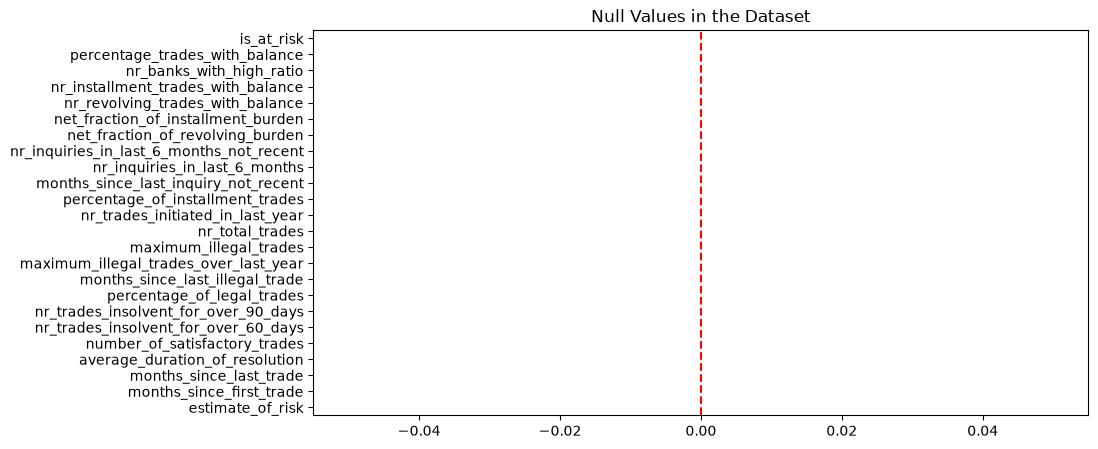

In [94]:
# checking null 
plt.figure(figsize=(10,5))
df.isnull().sum().plot(kind='barh')
plt.title('Null Values in the Dataset')
plt.axvline(0,color='r',linestyle='--')
plt.show()

In [95]:
# checking  duplicate values
df.duplicated().sum()
# 587 duplicates present

# removing duplicates
df = df.drop_duplicates()

# again checking  duplicate values
df.duplicated().sum()  #0

np.int64(0)

<Axes: >

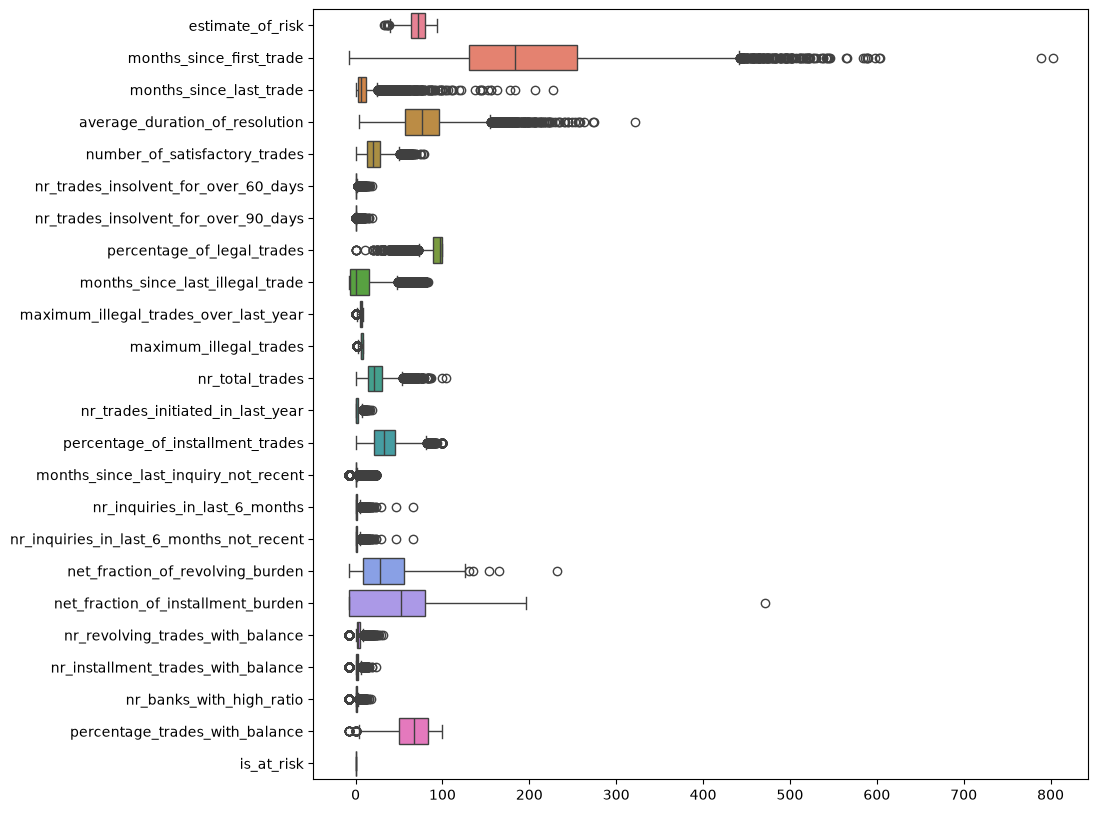

In [96]:
# Checking outlieras using Boxplot
plt.figure(figsize=(10,10))
sns.boxplot(df,orient='h')

In [97]:
# outliers handling
from collections import OrderedDict
outlier = []
for i in df.columns:
    Q1 = df[i].quantile(0.25)
    Q3 = df[i].quantile(0.75)
    
    IQR = Q3-Q1
    
    LW = Q1 - 1.5*IQR
    UW = Q3 + 1.5*IQR
    
    order = OrderedDict({
        'feature': df[i].name,
        'no. of Outlier': ((df[i] < LW) | (df[i] > UW)).sum(),
        'outlier %': (((df[i] < LW) | (df[i] > UW)).sum()/len(df[i]))*100,
    })
    outlier.append(order)
outlier_report = pd.DataFrame(outlier)
outlier_report

,feature,no. of Outlier,outlier %
0,estimate_of_risk,6,0.060852
1,months_since_first_trade,166,1.683570
2,months_since_last_trade,641,6.501014
3,average_duration_of_resolution,262,2.657201
4,number_of_satisfactory_trades,168,1.703854
5,nr_trades_insolvent_for_over_60_days,572,5.801217
6,nr_trades_insolvent_for_over_90_days,2226,22.576065
7,percentage_of_legal_trades,693,7.028398
8,months_since_last_illegal_trade,694,7.038540
9,maximum_illegal_trades_over_last_year,388,3.935091


In [98]:
# checking data with outliers
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
    
IQR = Q3-Q1
    
LW = Q1 - 1.5*IQR
UW = Q3 + 1.5*IQR




In [99]:
# checking Descriptive Stats of data using orderedict
from collections import OrderedDict

stats = []
for i in df.columns:
    order = OrderedDict({
        'Feature':df[i].name,
        'Count':df[i].count(),
        'Min':df[i].min(),
        'Max':df[i].max(),
        'Mean':df[i].mean(),
        'Median':df[i].median(),
        'Q1':df[i].quantile(0.25),
        'Q3':df[i].quantile(0.75),
        'IQR':df[i].quantile(0.75)-df[i].quantile(0.25),
        'Std':df[i].std(),
        'Variance':df[i].var(),
        'Skewness':df[i].skew(),
        'Kurtosis':df[i].kurtosis()
    })
    stats.append(order)
    
report = pd.DataFrame(stats)
report

,Feature,Count,Min,Max,Mean,Median,Q1,Q3,IQR,Std,Variance,Skewness,Kurtosis
0,estimate_of_risk,9860,33,94,72.061258,72.0,64.00,80.00,16.00,9.871962,97.455624,0.001163,-0.761332
1,months_since_first_trade,9860,-8,803,195.761258,183.0,131.00,255.00,124.00,101.917734,10387.224465,0.556978,0.530942
2,months_since_last_trade,9860,0,227,9.519675,6.0,3.00,12.00,9.00,12.288561,151.008742,5.293483,50.143271
3,average_duration_of_resolution,9860,4,322,78.739655,76.0,57.00,96.25,39.25,33.903302,1149.433887,0.861655,2.118770
4,number_of_satisfactory_trades,9860,0,79,21.130933,20.0,13.00,28.00,15.00,11.303304,127.764679,0.797526,0.827316
5,nr_trades_insolvent_for_over_60_days,9860,0,19,0.580426,0.0,0.00,1.00,1.00,1.238036,1.532734,4.178157,28.710273
6,nr_trades_insolvent_for_over_90_days,9860,0,19,0.383773,0.0,0.00,0.00,0.00,0.991893,0.983853,5.471870,51.668108
7,percentage_of_legal_trades,9860,0,100,92.363590,97.0,89.00,100.00,11.00,11.761067,138.322703,-2.431550,7.921772
8,months_since_last_illegal_trade,9860,-8,83,7.709736,0.0,-7.00,15.00,22.00,20.736131,429.987145,1.589421,1.817507
9,maximum_illegal_trades_over_last_year,9860,0,9,5.758316,6.0,5.00,7.00,2.00,1.641555,2.694702,-1.782362,3.204711


In [100]:
# 